# Positional effect platemaps

We check if the healthy predicted probability from the all hearts binary model (`model_all_hearts_final_downsample`) shifts across the plate.
The model is applied to only the testing and holdout cells from the plate it was trained on (cells from the training split are removed).
The probabilities are then averaged per well.

Each well is colored by the mean healthy predicted probability (0 = failing, 1 = healthy), the shape of the well shows the heart failure subtype, and the heart number is labeled inside the well.

In [1]:
import os
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import load
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.lines import Line2D
from scipy.stats import spearmanr


def plot_probability_platemap(
    plate_well_df: pd.DataFrame,
    ax: plt.Axes,
    title: str,
) -> plt.cm.ScalarMappable:
    """
    Plot a 96-well platemap with the wells colored by the mean healthy predicted probability,
    shaped by the heart failure subtype, and labeled with the heart number.

    Args:
        plate_well_df (pd.DataFrame): Well-level probabilities for one plate.
        ax (plt.Axes): Axes to plot the platemap on.
        title (str): Title for the platemap.

    Returns:
        plt.cm.ScalarMappable: Color mapping used for the wells (for the colorbar).
    """
    # Empty outline for the wells without cells
    used_wells = set(zip(plate_well_df["row_idx"], plate_well_df["col_idx"]))
    empty_wells = [
        (row, col)
        for row in range(len(plate_rows))
        for col in range(1, len(plate_cols) + 1)
        if (row, col) not in used_wells
    ]
    ax.scatter(
        [col for _, col in empty_wells],
        [row for row, _ in empty_wells],
        s=well_size,
        facecolors="none",
        edgecolors="#d9d9d6",
        linewidths=0.8,
    )

    for subtype, marker in subtype_markers.items():
        subtype_df = plate_well_df[plate_well_df["Metadata_heart_failure_type"] == subtype]
        ax.scatter(
            subtype_df["col_idx"],
            subtype_df["row_idx"],
            c=subtype_df["mean_healthy_probability"],
            cmap=probability_cmap,
            vmin=0,
            vmax=1,
            marker=marker,
            s=well_size * subtype_marker_scale[subtype],
            edgecolors="#4d4d4b",
            linewidths=0.8,
        )

    # Label each well with the heart number, using dark or light text for contrast with the fill
    for _, well in plate_well_df.iterrows():
        fill = to_rgb(probability_cmap(well["mean_healthy_probability"]))
        luminance = 0.2126 * fill[0] + 0.7152 * fill[1] + 0.0722 * fill[2]
        ax.text(
            well["col_idx"],
            well["row_idx"],
            well["well_label"],
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="#1a1a1a" if luminance > 0.5 else "white",
        )

    ax.set_xlim(0.4, len(plate_cols) + 0.6)
    ax.set_ylim(len(plate_rows) - 0.4, -0.6)
    ax.set_xticks(range(1, len(plate_cols) + 1))
    ax.set_yticks(range(len(plate_rows)))
    ax.set_yticklabels(plate_rows)
    ax.xaxis.tick_top()
    ax.tick_params(length=0, labelsize=10, colors="#555555")
    ax.set_aspect("equal")
    for spine in ax.spines.values():
        spine.set_color("#999999")
    ax.set_title(title, fontsize=12, loc="left", pad=24)

    return plt.cm.ScalarMappable(cmap=probability_cmap, norm=plt.Normalize(0, 1))


def add_platemap_legends(
    fig: plt.Figure, ax: plt.Axes, mappable: plt.cm.ScalarMappable, well_label_note: str
) -> None:
    """
    Add the subtype shape legend and the predicted probability colorbar right next to a platemap.

    Args:
        fig (plt.Figure): Figure with the platemap(s).
        ax (plt.Axes): Platemap axes to place the legends next to (top platemap if multiple).
        mappable (plt.cm.ScalarMappable): Color mapping used for the wells.
        well_label_note (str): Note explaining the label inside each well.
    """
    ax_pos = ax.get_position()
    legend_x = ax_pos.x1 + 0.02

    shape_handles = [
        Line2D(
            [],
            [],
            marker=marker,
            linestyle="",
            markersize=15 * np.sqrt(subtype_marker_scale[subtype]),
            markerfacecolor="white",
            markeredgecolor="#4d4d4b",
            # Healthy hearts are shown as non-failing
            label="Non-failing" if subtype == "Healthy" else subtype,
        )
        for subtype, marker in subtype_markers.items()
    ]
    leg = fig.legend(
        handles=shape_handles,
        title="Heart failure subtype",
        loc="upper left",
        bbox_to_anchor=(legend_x, ax_pos.y1),
        frameon=False,
        alignment="left",
        fontsize=10,
        title_fontsize=10,
        labelspacing=1.0,
        borderaxespad=0,
    )
    leg.get_title().set_fontweight("bold")

    # Note that the number inside each well is the heart number, placed below the legend
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    to_fig = fig.transFigure.inverted()
    legend_bottom = leg.get_window_extent(renderer).transformed(to_fig).y0
    note = fig.text(
        legend_x,
        legend_bottom - 0.01,
        well_label_note,
        ha="left",
        va="top",
        fontsize=9,
        color="#555555",
    )
    note_bottom = note.get_window_extent(renderer).transformed(to_fig).y0

    # Colorbar below the legend, with a fixed height in inches so it looks the same in every figure
    cbar_height = 2.4 / fig.get_figheight()
    cbar_top = note_bottom - 0.6 / fig.get_figheight()
    cbar_ax = fig.add_axes(
        [legend_x, cbar_top - cbar_height, 0.18 / fig.get_figwidth(), cbar_height]
    )
    cbar = fig.colorbar(mappable, cax=cbar_ax)
    cbar.ax.set_title(
        "Mean non-failing\nprobability",
        fontsize=10,
        fontweight="bold",
        loc="left",
        pad=8,
    )
    cbar.set_ticks([0, 0.25, 0.5, 0.75, 1])
    cbar.ax.tick_params(labelsize=9)
    cbar.outline.set_visible(False)

## Set paths and variables

In [2]:
# Set the plate to process with the PLATE_TO_TRAIN environment variable (defaults to the subtyping plate)
plate_trained = os.environ.get("PLATE_TO_TRAIN", "CARD-CelIns-CX7_260814100001")

# Model to apply and the label encoder used during training
model_path = pathlib.Path(
    f"models/{plate_trained}/model_all_hearts_final_downsample.joblib"
).resolve(strict=True)
encoder_path = pathlib.Path(
    f"encoder_results/{plate_trained}/label_encoder_global.joblib"
).resolve(strict=True)

# Training split used to remove the training cells from the plate
training_split_path = pathlib.Path(
    f"data_splits/{plate_trained}/training_split.parquet"
).resolve(strict=True)

# Normalized profiles for the training plate (can be in a subfolder, e.g. hlhs/)
normalized_path = next(
    pathlib.Path("../3.preprocessing_profiles/data/single_cell_profiles")
    .resolve(strict=True)
    .rglob(f"{plate_trained}_sc_normalized.parquet")
)

# Output directories for the well-level probabilities and figures
performance_metrics_dir = pathlib.Path(f"performance_metrics/{plate_trained}")
performance_metrics_dir.mkdir(parents=True, exist_ok=True)
figure_dir = pathlib.Path(f"figures/{plate_trained}")
figure_dir.mkdir(parents=True, exist_ok=True)

# Columns that uniquely identify a single cell
cell_id_cols = [
    "Metadata_Plate",
    "Metadata_Well",
    "Metadata_Site",
    "Metadata_Nuclei_Number_Object_Number",
]

# 96-well plate layout
plate_rows = list("ABCDEFGH")
plate_cols = list(range(1, 13))
well_size = 1350

# Shape of the well per heart failure subtype (squares/diamonds are scaled to look the same size as circles)
subtype_markers = {"Healthy": "o", "DCM": "s", "ICM": "D", "HLHS": "^"}
subtype_marker_scale = {"Healthy": 1.0, "DCM": 0.8, "ICM": 0.62, "HLHS": 0.75}

# Female hearts (all other hearts are male)
female_hearts = [32, 64]

# Sequential colormap (one hue, light to dark) for the healthy probability from 0 to 1
probability_cmap = LinearSegmentedColormap.from_list(
    "healthy_probability", ["#edf6ee", "#b5dbb9", "#6fb87a", "#2e8b47", "#0f4d27"]
)

## Apply the model to only the testing and holdout cells

In [3]:
model = load(model_path)
label_encoder = load(encoder_path)

# Index of the healthy class in the predicted probabilities
healthy_index = list(model.classes_).index(
    label_encoder.transform(["Healthy"])[0]
)

# Remove the cells from the training split
plate_df = pd.read_parquet(normalized_path).merge(
    pd.read_parquet(training_split_path, columns=cell_id_cols).assign(in_training=True),
    on=cell_id_cols,
    how="left",
)
n_training_cells = plate_df["in_training"].notna().sum()
plate_df = plate_df[plate_df["in_training"].isna()]

# Apply the model with the features (in the same order) it was trained on
cell_prob_df = plate_df[
    [
        "Metadata_Plate",
        "Metadata_Well",
        "Metadata_heart_number",
        "Metadata_heart_failure_type",
        "Metadata_cell_type",
    ]
].assign(
    healthy_probability=model.predict_proba(plate_df[model.feature_names_in_])[
        :, healthy_index
    ]
)

# Healthy hearts have no heart failure type, so label them as Healthy
cell_prob_df["Metadata_heart_failure_type"] = cell_prob_df[
    "Metadata_heart_failure_type"
].fillna("Healthy")

# Only show the subtypes on this plate
subtype_markers = {
    subtype: marker
    for subtype, marker in subtype_markers.items()
    if subtype in set(cell_prob_df["Metadata_heart_failure_type"])
}

pd.DataFrame(
    {
        "n_training_cells_removed": [n_training_cells],
        "n_cells_included": [len(cell_prob_df)],
    }
)

,n_training_cells_removed,n_cells_included
0,3383,3290


In [4]:
# Aggregate to the well-level (mean healthy predicted probability per well)
well_prob_df = (
    cell_prob_df.groupby(
        [
            "Metadata_Plate",
            "Metadata_Well",
            "Metadata_heart_number",
            "Metadata_heart_failure_type",
            "Metadata_cell_type",
        ]
    )["healthy_probability"]
    .agg(mean_healthy_probability="mean", n_cells="size")
    .reset_index()
)
# Heart numbers are compared as strings since some plates use letters
well_prob_df["Metadata_heart_number"] = well_prob_df["Metadata_heart_number"].astype(str)

# Label each well with the heart number and sex (M = male, F = female) when the plate has the female
# hearts, otherwise only the heart number (sex is not known for all hearts on the other plates)
is_female = well_prob_df["Metadata_heart_number"].isin(map(str, female_hearts))
if is_female.any():
    well_prob_df["well_label"] = well_prob_df["Metadata_heart_number"] + np.where(is_female, "F", "M")
    well_label_note = "Label in well = heart number and sex\n(M = male, F = female)"
else:
    well_prob_df["well_label"] = well_prob_df["Metadata_heart_number"]
    well_label_note = "Label in well = heart number"
well_prob_df["row_idx"] = well_prob_df["Metadata_Well"].str[0].map(plate_rows.index)
well_prob_df["col_idx"] = well_prob_df["Metadata_Well"].str[1:].astype(int)

well_prob_df.to_parquet(
    performance_metrics_dir / "positional_effect_well_probabilities.parquet",
    index=False,
)

# Summary of the well-level probabilities per heart failure subtype
well_prob_df.groupby("Metadata_heart_failure_type")["mean_healthy_probability"].agg(
    ["mean", "min", "max", "count"]
).loc[list(subtype_markers)]

,mean,min,max,count
Metadata_heart_failure_type,,,,
Healthy,0.776309,0.213922,0.988316,30
DCM,0.309233,0.020879,0.753462,15
ICM,0.103632,0.001582,0.242061,15


## Check for a positional trend

Within each cell type, we compute the Spearman correlation between the well-level healthy probability and the plate row and column.
A strong correlation would suggest the predictions shift across the plate.

In [5]:
positional_results = []
for cell_type, group_df in well_prob_df.groupby("Metadata_cell_type"):
    for position in ["row_idx", "col_idx"]:
        rho, p_value = spearmanr(group_df[position], group_df["mean_healthy_probability"])
        positional_results.append(
            {
                "cell_type": cell_type,
                "position": "row" if position == "row_idx" else "column",
                "spearman_rho": rho,
                "p_value": p_value,
                "n_wells": len(group_df),
            }
        )

pd.DataFrame(positional_results)

,cell_type,position,spearman_rho,p_value,n_wells
0,Failing,row,0.307532,0.098292,30
1,Failing,column,0.004483,0.981243,30
2,Healthy,row,0.314075,0.090982,30
3,Healthy,column,-0.169788,0.369725,30


## Generate the platemap

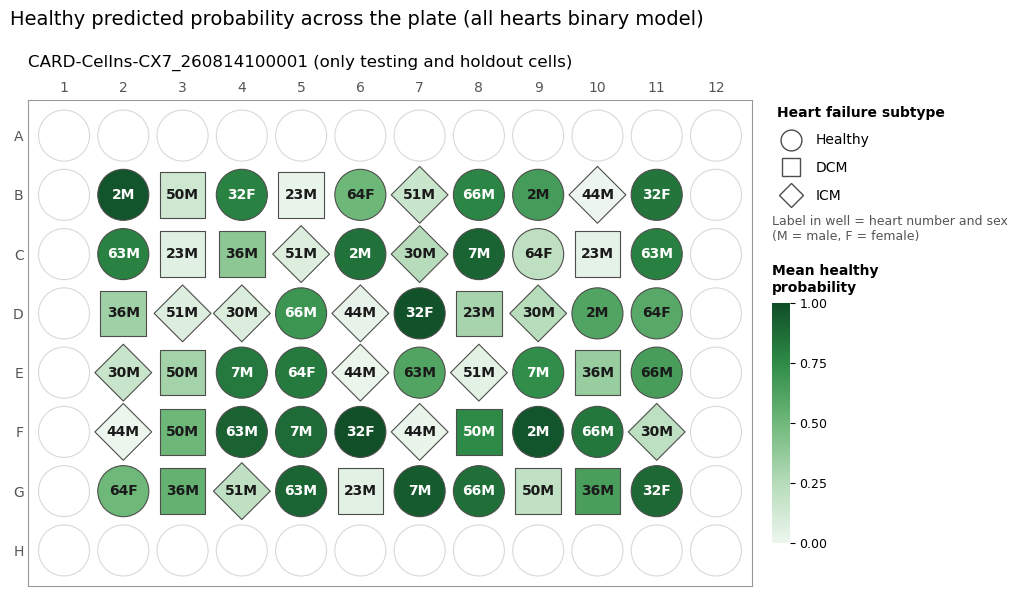

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
fig.subplots_adjust(left=0.04, right=0.80, top=0.84, bottom=0.03)
mappable = plot_probability_platemap(
    well_prob_df, ax=ax, title=f"{plate_trained} (only testing and holdout cells)"
)
fig.suptitle(
    "Non-failing predicted probability across the plate (all hearts binary model)",
    x=0.04,
    y=0.99,
    ha="left",
    fontsize=14,
)
add_platemap_legends(fig, ax, mappable, well_label_note)

fig.savefig(
    figure_dir / "positional_effect_platemap_all_hearts_model.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()